In [1]:
import warnings
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import statsmodels.api as sm 
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore', category = FutureWarning)
plt.rcParams["figure.figsize"] = (11, 3.4)

In [2]:
URL = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
raw = pd.read_csv(URL, comment="#")  # or the Canvas copy: pd.read_csv("co2_mm_mlo.csv", comment="#")
raw.tail()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
818,2026,5,2026.3750,432.34,429.05,19,0.64,0.28
819,2026,6,2026.4583,431.43,429.00,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.74,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.48,17,0.38,0.18
822,2026,9,2026.7083,426.07,429.55,18,0.51,0.23


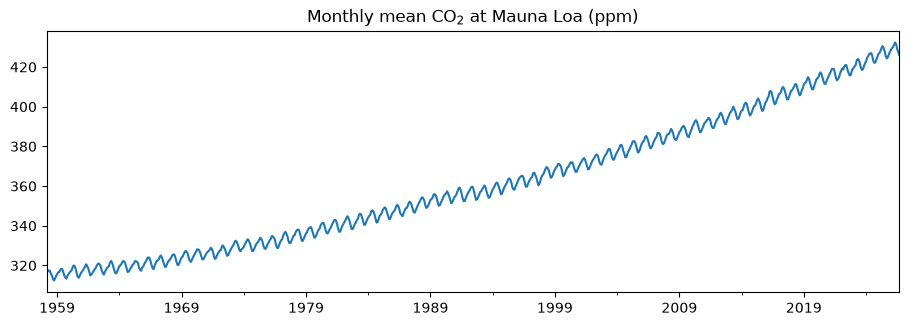

In [3]:
raw.index = pd.to_datetime(raw[["year", "month"]].assign(day=1))
raw = raw.asfreq("MS")  # one row per month, dated at the start
co2 = raw["average"]  # monthly mean CO2, in ppm
co2.plot(title="Monthly mean CO$_2$ at Mauna Loa (ppm)")
plt.show()